In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, log_loss
import matplotlib.pyplot as plt
import os
from sklearn.metrics import log_loss

In [2]:
class Config:
    DATA_DIR= '../data'
    VER= 'v1'
    OUTPUT_DIR='../outputs'

In [3]:
train = pd.read_csv(f'{Config.DATA_DIR}/Train.csv')
test = pd.read_csv(f'{Config.DATA_DIR}/Test.csv')
ss = pd.read_csv(f'{Config.DATA_DIR}/SampleSubmission.csv')

target_col = 'income_above_limit'
train[target_col] = train[target_col].map({'Below limit': 0, 'Above limit': 1})

In [4]:
train_preds_df = pd.DataFrame()
test_preds_df = pd.DataFrame()

for ver in ['v8', 'v9',  'v12', 'v13']:
    train_preds_df[ver] = pd.read_csv(f'{Config.OUTPUT_DIR}/train_preds_{ver}.csv')['preds']
    test_preds_df[ver] = pd.read_csv(f'{Config.OUTPUT_DIR}/test_preds_{ver}.csv')['preds']

In [5]:
log_loss(train[target_col], train_preds_df['v8'])

0.1060184380808056

In [6]:
def get_final_preds(df):
    
    df['final_preds'] = (df['v8']*0.5 + df['v9']*0.5)*0.45 + (df['v12'] * 0.5 + df['v13'] * 0.5)*0.55
    return df

In [7]:
train_preds_df = get_final_preds(train_preds_df)
test_preds_df = get_final_preds(test_preds_df)

In [8]:
log_loss(train[target_col], train_preds_df['final_preds'])

0.10548203237650183

In [9]:
def plot_f1_against_thresholds(y_true, y_pred):
    global threshold
    
    scores = {}
    thresholds = np.arange(0, 1.01, 0.005)
    
    for threshold in thresholds:
        scores[threshold] = f1_score(y_true, y_pred > threshold)
        
    print(np.max(pd.Series(scores).values))
    print(thresholds[np.argmax(pd.Series(scores))])
        
    threshold = thresholds[np.argmax(pd.Series(scores))]
    return plt.plot(list(scores.keys()), list(scores.values()))

0.6470365029976473
0.305


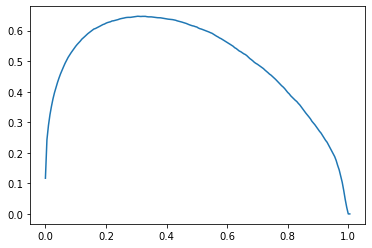

In [10]:
plot_f1_against_thresholds(train[target_col], train_preds_df['final_preds'])

In [11]:
f1_score(train[target_col], train_preds_df['final_preds'] > 0.305)

0.6470365029976473

In [12]:
ss['income_above_limit'] = (test_preds_df['final_preds'].values > 0.305)*1
ss['income_above_limit'].value_counts(normalize=True)

0    0.936104
1    0.063896
Name: income_above_limit, dtype: float64

In [13]:
ss.to_csv(os.path.join(Config.OUTPUT_DIR, f'blend_sub_{Config.VER}.csv'), index=False)